# RETAIL SALES DATA ANALYSIS

## 1. Introduction

This project analyses retail sales data to understand sales
performance, customer demographics, product categories and
purchasing patterns. Python libraries are used to perform
statistical analysis and data visualisation.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualisation style
sns.set_style("whitegrid")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

The retail sales dataset is imported into Python using
the Pandas library.

In [6]:
df = pd.read_csv("retail_sales_dataset.csv")

# Display first five records
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 3. Initial Data Inspection

The dataset is examined to understand its dimensions,
column data types and completeness before performing
further analysis.

In [9]:
print("Number of Rows and Columns:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Number of Rows and Columns: (1000, 9)
Total Rows: 1000
Total Columns: 9


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [13]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values: 0


In [15]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


### Observation

The dataset contains 1,000 records and 9 columns.
There are no missing values or duplicate rows.
The Date column is initially stored as an object data type
and must be converted into datetime format for time-series
analysis. The remaining numerical and categorical columns
are suitable for further analysis.

## 4. Data Cleaning and Preparation

The Date column is converted into datetime format to
facilitate monthly and quarterly sales analysis.

In [18]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Check data types after conversion
print(df.dtypes)

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [20]:
# Extract month and quarter
df['Month'] = df['Date'].dt.to_period('M')

df['Quarter'] = df['Date'].dt.to_period('Q')

# Create customer age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Quarter,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023-11,2023Q4,26-35
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023-02,2023Q1,26-35
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023-01,2023Q1,46-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023-05,2023Q2,36-45
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023-05,2023Q2,26-35


## 5. Descriptive Statistical Analysis

Descriptive statistics are used to summarise the numerical
variables in the dataset. Mean, median, mode and standard
deviation are calculated to understand the distribution
and variation of the data.

In [22]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

# Calculate descriptive statistics
statistics = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Standard Deviation': df[numerical_columns].std()
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


### Observation

Descriptive statistics provide an overview of the
distribution of sales, customer age, quantity and
unit prices. Comparing the mean and median helps identify
whether the numerical variables are affected by unusually
high or low values. Standard deviation indicates the
variation in customer purchases and transaction amounts.

## 6. Time-Series Analysis

Time-series analysis is performed to identify changes
in sales performance over different periods.
Monthly and quarterly sales trends are examined using
line charts.

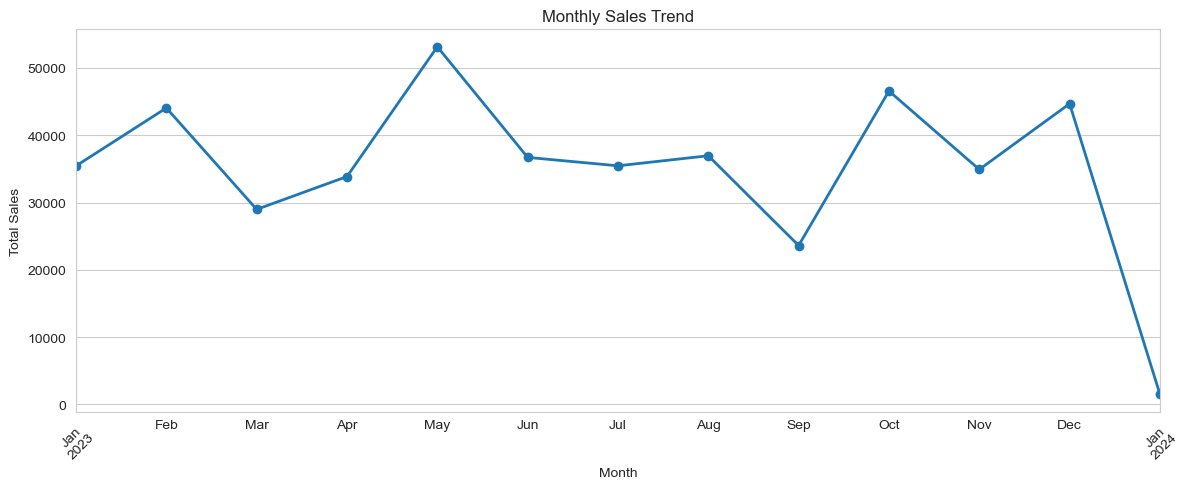

In [25]:
# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

# Plot monthly sales
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

### Observation

The monthly sales trend illustrates the fluctuations
in revenue throughout the year. Months with higher
sales indicate stronger purchasing activity, whereas
months with lower sales may indicate reduced customer
demand. These variations can help the business identify
periods that require promotional activities.

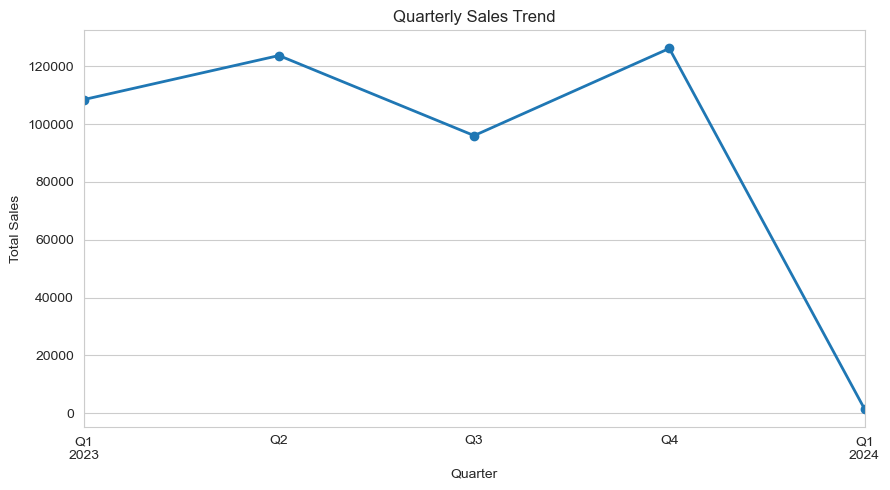

In [27]:
# Calculate quarterly sales
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Plot quarterly sales
plt.figure(figsize=(9, 5))

quarterly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)

plt.tight_layout()
plt.show()

### Observation

The quarterly sales trend provides a broader view
of business performance. It helps identify which
quarter generated the highest and lowest revenue.
This information can support quarterly budgeting,
inventory planning and sales forecasting.

C:\Users\Asghar\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


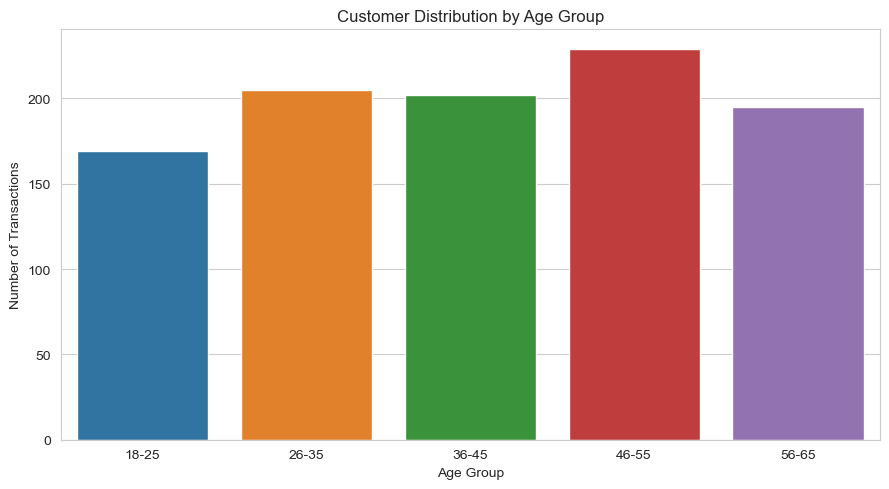

In [29]:
# Count customers by age group
age_distribution = df['Age Group'].value_counts().sort_index()

# Plot age distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_distribution.index,
    y=age_distribution.values
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

### Observation

The age-group distribution highlights the purchasing
participation of different customer age segments.
The largest age group represents the segment with
the highest number of recorded transactions.
This information can help the business identify its
major customer segments and develop targeted marketing
strategies.

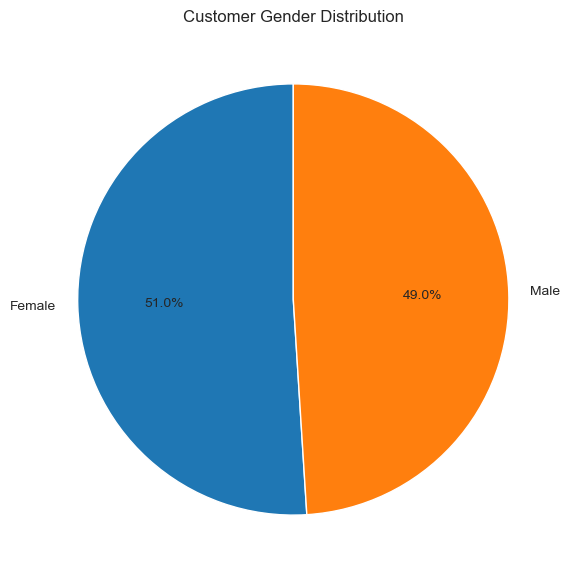

In [31]:
# Calculate gender distribution
gender_distribution = df['Gender'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    gender_distribution.values,
    labels=gender_distribution.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')

plt.show()

In [ ]:
### Observation

The gender distribution represents the proportion
of transactions made by male and female customers.
The results help identify the participation of
different gender groups in retail purchases.
A balanced distribution may indicate that the
business attracts customers from both segments.

Best-Selling Product Categories:
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


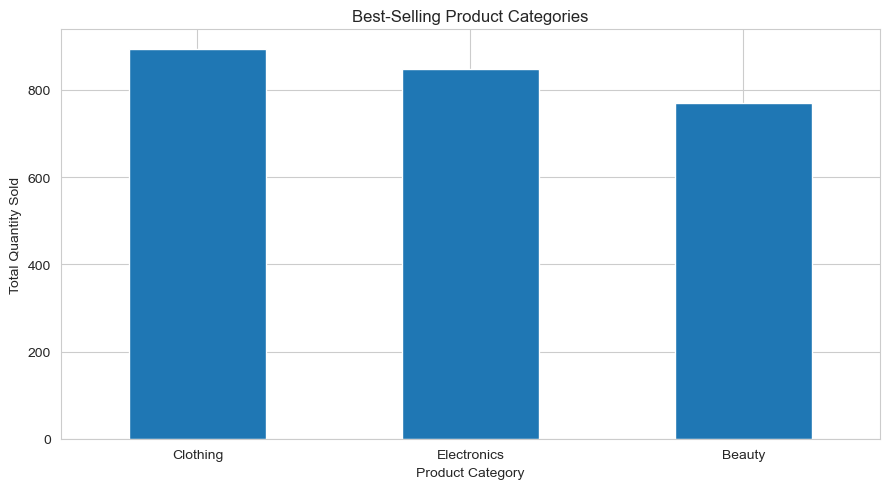

In [33]:
# Calculate quantity sold by category
best_selling = df.groupby(
    'Product Category'
)['Quantity'].sum().sort_values(ascending=False)

print("Best-Selling Product Categories:")
print(best_selling)

# Plot the results
plt.figure(figsize=(9, 5))

best_selling.plot(
    kind='bar'
)

plt.title('Best-Selling Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

The analysis identifies the product categories
with the highest sales volume based on total
quantity sold. The leading category represents
the strongest demand in terms of units purchased.
The business can use this information to improve
inventory allocation and product availability.

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


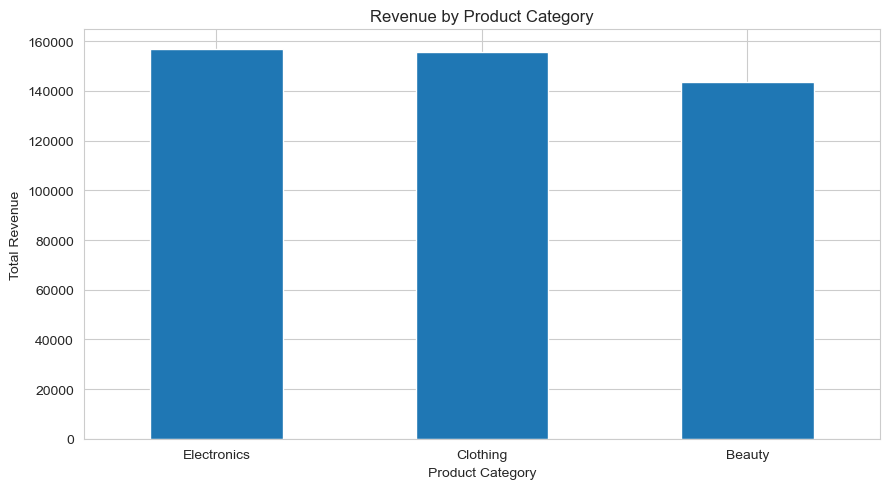

In [35]:
# Calculate revenue by category
category_revenue = df.groupby(
    'Product Category'
)['Total Amount'].sum().sort_values(ascending=False)

print(category_revenue)

# Create bar chart
plt.figure(figsize=(9, 5))

category_revenue.plot(
    kind='bar'
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

The revenue analysis compares the financial
contribution of different product categories.
The category generating the highest revenue
represents the largest contributor to overall
sales. Comparing revenue with quantity sold
can also help identify categories with different
average selling prices.

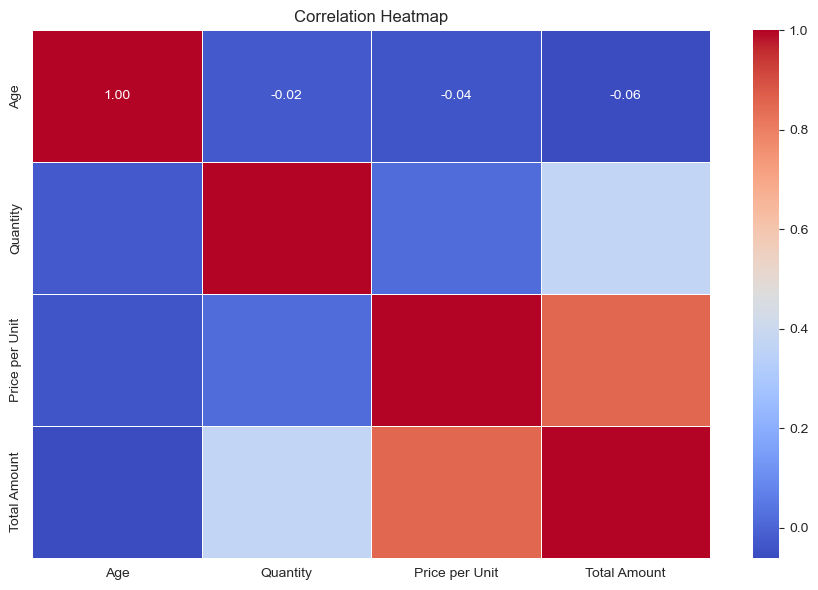

In [37]:
# Select meaningful numerical variables
correlation_columns = [
    'Age',
    'Quantity',
    'Price per Unit',
    'Total Amount'
]

# Calculate correlation matrix
correlation_matrix = df[
    correlation_columns
].corr()

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

## 8. Correlation Analysis

Correlation analysis is performed to identify
relationships between numerical variables.
A heatmap is used to visually represent the
correlation coefficients.

### Observation

The correlation heatmap illustrates the strength
and direction of relationships between numerical
variables. Positive correlations indicate that
two variables tend to increase together, whereas
negative correlations indicate an inverse relationship.

A strong correlation between quantity and total
amount would suggest that purchasing more units
is associated with higher transaction revenue.
However, correlation does not establish causation.

Gender     Female   Male
Age Group               
18-25       39470  45080
26-35       55115  43365
36-45       46735  45135
46-55       53310  47380
56-65       38210  42200


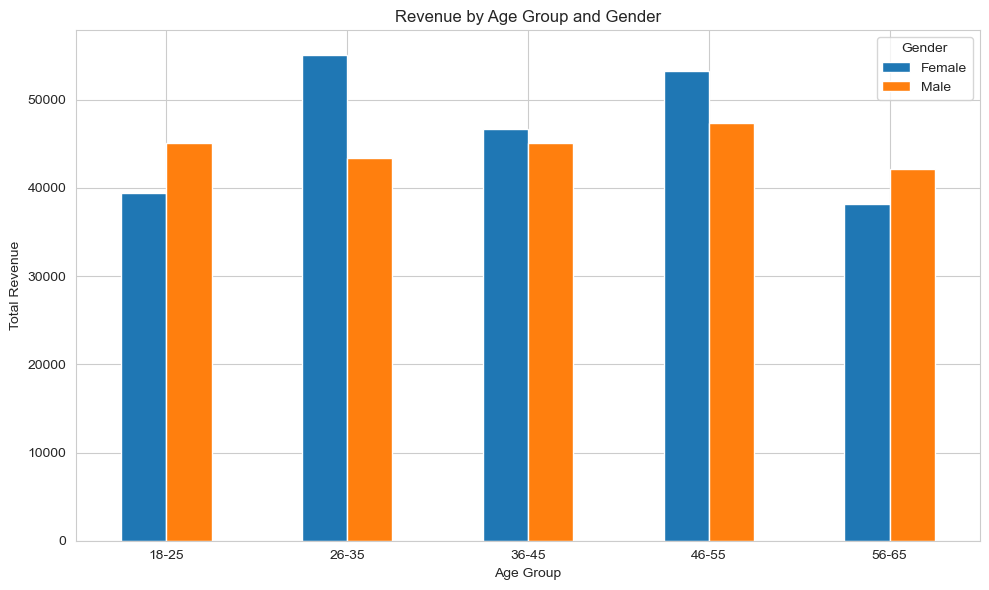

In [39]:
# Group revenue by age group and gender
customer_spending = df.pivot_table(
    index='Age Group',
    columns='Gender',
    values='Total Amount',
    aggfunc='sum',
    observed=False
)

print(customer_spending)

# Create grouped bar chart
customer_spending.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Revenue by Age Group and Gender')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.legend(title='Gender')

plt.tight_layout()
plt.show()

## 9. Additional Analysis – Customer Spending Patterns

This analysis examines revenue generated by different
age groups across gender categories. It helps identify
customer segments that contribute significantly to
the business's overall revenue.

### Observation

The chart compares revenue contributions across
different age groups and gender categories.
It helps identify which demographic segments
generate higher sales revenue.

The business can use these findings to develop
targeted promotional campaigns and improve
customer segmentation strategies.

# 10. Conclusion and Business Recommendations

## Conclusion

The retail sales analysis provides insights into
sales performance, customer demographics, product
category performance and purchasing behaviour.

The analysis helps identify revenue-generating
product categories, customer segments and variations
in sales across different periods.

## Business Recommendations

1. Inventory Management:
   The business should prioritise stock availability
   for Clothing, which recorded the highest quantity
   sold, while monitoring demand for other categories.

2. Revenue Optimisation:
   Electronics generated the highest revenue.
   The business should focus on maintaining product
   availability and developing promotional strategies
   for this category.

3. Customer Segmentation:
   The 46-55 age group recorded the highest number
   of transactions. The business should develop
   targeted marketing campaigns to retain and attract
   customers in this segment.

4. Seasonal Sales Planning:
   The business should examine high-performing
   months and quarters to plan inventory, staffing
   and promotional activities more effectively.

5. Gender-Based Marketing:
   Female customers contributed slightly more
   revenue than male customers. The business should
   investigate purchasing preferences across both
   segments before designing targeted campaigns.

Overall, data-driven decision-making can help
improve inventory planning, customer engagement
and revenue generation.